# 04 · D · Laisser faire les arbres

*Module 14 « Feature engineering & transformation » · TD du mercredi 21 octobre 2026 · environ 15 minutes en salle.*

### Ce qu'on fait

On donne aux cinq modèles les 25 colonnes brutes autorisées, presque sans préparation : chaque
catégorielle devient un code entier, et rien n'est mis à l'échelle. C'est la préparation qui suffit aux arbres. On
mesure ce qu'elle leur rapporte, et ce qu'elle coûte aux trois autres familles de modèles.

### Les choix de cette approche

| Décision | Choix | Pourquoi |
|---|---|---|
| Variables | les 25 colonnes brutes autorisées (`NUMERIQUES` + `CATEGORIELLES`), aucune variable créée | on regarde ce que les arbres trouvent seuls |
| Catégorielles | `OrdinalEncoder` : un code entier par modalité, dans l'ordre alphabétique | un arbre isole une modalité en quelques coupes ; une colonne par variable au lieu de dizaines |
| Modalités rares, inconnues, manquantes | `min_frequency=20` regroupe les rares ; les inconnues et les manquantes reçoivent le code −1 | le service ne plante pas sur un pays jamais vu ; moins de 255 codes par colonne, comme l'exige le support natif |
| Mise à l'échelle | aucune | un arbre compare une variable à un seuil : seul l'ordre des valeurs compte |
| Manquants numériques | la médiane du train (seule `children` en a) | la régression logistique, le kNN et le réseau refusent les valeurs manquantes |
| Boosting | `HistGradientBoostingClassifier(categorical_features=CATEGORIELLES)` à la place du boosting standard | le support natif regroupe les modalités au lieu de suivre l'ordre arbitraire des codes |
| Les trois autres familles | mêmes modèles, mêmes réglages (`modeles()`), même préparation | mesurer ce que ces choix leur coûtent |
| Noms de colonnes | `verbose_feature_names_out=False` et `.set_output(transform="pandas")` | le boosting désigne ses catégorielles par leur nom |

### Les outils utilisés

- `OrdinalEncoder` (`min_frequency`, `handle_unknown="use_encoded_value"`, `encoded_missing_value`) : cours 1,
  slides 19 et 21.
- `HistGradientBoostingClassifier(categorical_features=...)`, le support natif des catégorielles : cours 1, slide 23.
- `SimpleImputer(strategy="median")`, appris sur le train : cours 1, slide 7.
- `ColumnTransformer`, `make_pipeline`, `.set_output(transform="pandas")` : cours 2, slide 24.
- `StandardScaler`, `RandomForestClassifier`, `KNeighborsClassifier` : qui est sensible à l'échelle, et qui ne
  l'est pas, cours 2, slides 3 et 5.
- `permutation_importance` (`sklearn.inspection`) : cours 2, slide 21 (encadré).
- `warnings.catch_warnings` et `ConvergenceWarning` : filtrer un avertissement attendu, et dire pourquoi.
- `fe_tp.evaluation.modeles()` et `evaluer()` : les cinq modèles et la mesure commune à toutes les approches ; la
  fiche réflexe du cours 2, slide 28.

### Ce qu'on regarde à la fin

Les AUC des cinq modèles avec 25 colonnes seulement : les arbres tiennent-ils le
niveau de l'approche A, qui en utilisait environ 365 ? De combien les trois autres familles chutent-elles ? Et
quelles colonnes le boosting utilise-t-il vraiment ?

## 1. Charger et découper

Mêmes données et même découpage temporel que dans les autres notebooks : le modèle apprend sur les arrivées
jusqu'au 21 avril 2017 et prédit les suivantes. On garde les 25 colonnes brutes autorisées, sans en créer aucune.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

from fe_tp.donnees import CATEGORIELLES, CIBLE, MOIS, NUMERIQUES, charger, decouper
from fe_tp.evaluation import evaluer, modeles

In [2]:
df = charger()
train, test = decouper(df)
X_train, y_train = train[NUMERIQUES + CATEGORIELLES], train[CIBLE]
X_test, y_test = test[NUMERIQUES + CATEGORIELLES], test[CIBLE]
print(f"train : {X_train.shape}, test : {X_test.shape}")
print(f"taux d'annulation : {y_train.mean():.3f} (train), {y_test.mean():.3f} (test)")

train : (95190, 25), test : (24018, 25)
taux d'annulation : 0.361 (train), 0.410 (test)


95 190 réservations pour apprendre, 24 018 pour tester, et les mêmes 25 colonnes des deux côtés. Le test annule
davantage que le train (41,0 % contre 36,1 %).

## 2. Numéroter, c'est inventer un ordre

`OrdinalEncoder` remplace chaque modalité par un entier. Sans liste `categories=[...]`, il range les modalités
par ordre alphabétique (cours 1, slide 19). Voici les codes qu'il donne aux mois.

In [3]:
ordinal = OrdinalEncoder(min_frequency=20, handle_unknown="use_encoded_value", unknown_value=-1,
                         encoded_missing_value=-1)
mois_alphabetiques = ordinal.fit(X_train[["arrival_date_month"]]).categories_[0]
pd.Series(range(12), index=mois_alphabetiques, name="code").to_frame().T

,April,August,December,February,January,July,June,March,May,November,October,September
code,0,1,2,3,4,5,6,7,8,9,10,11


Avril reçoit 0, août 1, décembre 2… et septembre 11. Janvier (4) se retrouve entre février (3) et juillet (5),
et mai (8) « dépasse » juin (6). Pour un modèle linéaire, décembre vaut désormais la moitié de janvier : on vient
d'inventer un calendrier.

Le taux d'annulation du train, mois par mois, rangé une fois dans l'ordre des codes et une fois dans l'ordre du
calendrier :

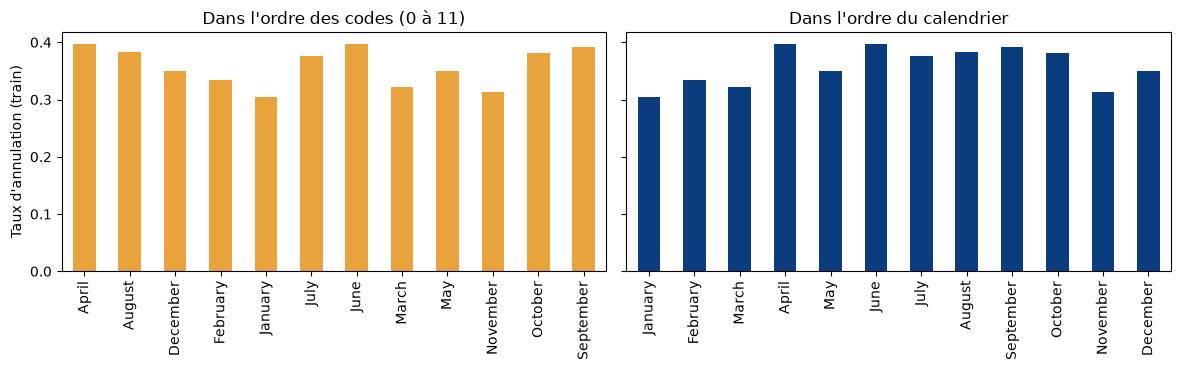

In [4]:
taux = train.groupby("arrival_date_month")[CIBLE].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
taux[mois_alphabetiques].plot.bar(ax=axes[0], color="#E8A33D", title="Dans l'ordre des codes (0 à 11)")
taux[list(MOIS)].plot.bar(ax=axes[1], color="#0B3C7D", title="Dans l'ordre du calendrier")
axes[0].set_ylabel("Taux d'annulation (train)")
for ax in axes:
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

À droite, le calendrier raconte une saison : environ 30 % d'annulations en janvier, entre 35 et 40 % d'avril à
octobre, puis environ 31 % en novembre. À gauche, les mêmes barres rangées par code dessinent un zigzag. Une
régression logistique sur le code ne peut tracer qu'une pente à travers ce zigzag ; un arbre, lui, découpe l'axe
en morceaux et retrouve chaque mois en quelques coupes.

Mesurons le coût de cet ordre inventé, une colonne à la fois. Le mois ne s'y prête pas : le test ne couvre que
d'avril à août. On prend donc `market_segment` (8 modalités) et `agent` (plus de 300). Le même code entier est
donné à une régression logistique et à un boosting ; le one-hot sert de référence.

In [5]:
candidats = {
    "Rég. logistique sur les codes": make_pipeline(clone(ordinal), LogisticRegression()),
    "Rég. logistique sur le one-hot": make_pipeline(
        OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=20), LogisticRegression()),
    "Boosting sur les codes": make_pipeline(clone(ordinal), HistGradientBoostingClassifier(random_state=0)),
}
aucs = {}
for colonne in ["market_segment", "agent"]:
    aucs[colonne] = {}
    for nom, pipe in candidats.items():
        pipe.fit(X_train[[colonne]], y_train)
        aucs[colonne][nom] = roc_auc_score(y_test, pipe.predict_proba(X_test[[colonne]])[:, 1])
pd.DataFrame(aucs).round(3)

,market_segment,agent
Rég. logistique sur les codes,0.535,0.508
Rég. logistique sur le one-hot,0.623,0.651
Boosting sur les codes,0.623,0.651


Sur les codes, la régression logistique tombe à 0,535 pour `market_segment` et à 0,508 pour `agent` : presque le
hasard (0,5). Elle cherche un risque qui monte ou qui descend avec le code, et cet ordre n'existe pas. Le one-hot
lui rend 0,623 et 0,651. Le boosting lit les mêmes codes que la régression et retrouve, à 0,001 près, les scores
du one-hot : en découpant l'axe des codes en morceaux, il isole chaque modalité.

> 💬 **Pour la salle.** Avec une seule colonne, le boosting s'accommode très bien de codes d'agents rangés dans
> un ordre arbitraire. Pourquoi est-ce moins facile quand il en a 25 ?
>
> *Piste : isoler un agent sur l'axe des codes demande deux coupes (« code ≥ 41 », puis « code < 42 »). Avec une
> seule colonne, toutes les coupes de ses 100 arbres lui sont consacrées. Avec 25 colonnes, ce budget se partage :
> chaque coupe dépensée à regrouper des agents dispersés dans l'ordre alphabétique manque ailleurs. C'est ce que le
> support natif évite (section 5).*

## 3. La préparation D : des codes, aucune échelle

Deux branches suffisent : la médiane pour les numériques, le code entier pour les catégorielles. Où sont les
valeurs manquantes du train ?

In [6]:
manquants = X_train.isna().sum()
manquants[manquants > 0]

children        4
country       473
agent       13730
company     89290
dtype: int64

Parmi les numériques, seule `children` a des manquants (4 sur 95 190) : la médiane suffit. Les autres trous sont
dans des catégorielles : `country` (473), `agent` (13 730) et surtout `company` (89 290, soit 94 % du train). Ils
recevront le code −1, comme les modalités jamais vues au train ; pour le boosting natif, un code négatif signifie
justement « manquant ».

Le `ColumnTransformer` de l'approche D. `verbose_feature_names_out=False` et `.set_output(transform="pandas")`
gardent les noms d'origine des colonnes : le boosting en aura besoin pour savoir lesquelles sont catégorielles.
On compare le nombre de modalités du train au nombre de codes distincts en sortie.

In [7]:
prep = ColumnTransformer(
    [("num", SimpleImputer(strategy="median"), NUMERIQUES), ("cat", ordinal, CATEGORIELLES)],
    verbose_feature_names_out=False,
).set_output(transform="pandas")
Z_train = prep.fit_transform(X_train)
print(f"{Z_train.shape[1]} colonnes en sortie")
pd.DataFrame({"modalités au train": X_train[CATEGORIELLES].nunique(),
              "codes en sortie (dont −1)": Z_train[CATEGORIELLES].nunique()})

25 colonnes en sortie


,modalités au train,codes en sortie (dont −1)
hotel,2,2
arrival_date_month,12,12
meal,5,5
country,165,72
market_segment,8,8
distribution_channel,5,5
reserved_room_type,9,9
deposit_type,3,3
customer_type,4,4
agent,311,171


25 colonnes en sortie, une par colonne d'entrée ; le one-hot de l'approche A en produisait 365 (notebook 01). Les
colonnes à forte cardinalité sont resserrées par `min_frequency=20` : `agent` passe de 311 modalités à 171 codes
(169 agents fréquents, un code commun aux 142 agents rares, et −1), `country` de 165 à 72, `company` de 328 à 60.
Toutes restent sous la limite de 255 modalités du support natif (`max_bins`). Attention à l'intitulé
« dont −1 » : au train, le code −1 n'apparaît que dans les trois colonnes qui ont des manquants (`country`,
`agent`, `company`). `hotel`, par exemple, a 2 codes, ceux de ses deux hôtels.

Aucune colonne n'est mise à l'échelle. Les plus grandes valeurs en sortie de la préparation :

In [8]:
Z_train.describe().T[["min", "max"]].sort_values("max", ascending=False).head(6)

,min,max
lead_time,0.0,737.0
adr,0.0,508.0
days_in_waiting_list,0.0,391.0
agent,-1.0,169.0
country,-1.0,70.0
previous_bookings_not_canceled,0.0,61.0


Rien n'a été mis à l'échelle : `lead_time` monte à 737 jours, `adr` à 508, `days_in_waiting_list` à 391, et les
codes d'`agent` vont de −1 à 169, à côté de colonnes qui valent 0 ou 1. Pour un arbre, c'est sans importance. Pour
une distance ou une descente de gradient, ces 737 jours écrasent tout le reste (cours 2, slide 3).

## 4. Les arbres ignorent l'échelle

Une distance additionne des unités différentes ; un arbre, lui, compare une variable à un seuil (cours 2,
slide 3). Standardiser déplace les seuils sans changer l'ordre des valeurs : l'arbre doit retrouver exactement
les mêmes coupes. On le vérifie avec la forêt aléatoire, et avec le kNN pour contraste.

In [9]:
aucs = {}
for nom in ["Forêt aléatoire", "kNN"]:
    aucs[nom] = {}
    for echelle, etapes in {"sans mise à l'échelle": [], "avec StandardScaler": [StandardScaler()]}.items():
        pipe = make_pipeline(clone(prep), *etapes, modeles()[nom]).fit(X_train, y_train)
        aucs[nom][echelle] = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
pd.DataFrame(aucs).T.round(4)

,sans mise à l'échelle,avec StandardScaler
Forêt aléatoire,0.8524,0.8524
kNN,0.7190,0.8013


La forêt obtient 0,8524 avec ou sans standardisation, identique à la quatrième décimale : l'ordre des valeurs n'a
pas changé, donc les coupes non plus. Le kNN, lui, passe de 0,7190 à 0,8013 : sans mise à l'échelle, ses
distances ne voyaient presque que `lead_time`, `adr` et les codes d'agents. Standardiser ne lui rend pas tout, car
les codes restent des numéros sans ordre réel : l'agent 41 n'est pas « voisin » de l'agent 42.

## 5. Le support natif des catégorielles

Sur des codes lus comme des nombres, une coupe « `agent` < 37 » regroupe des agents qui n'ont rien en commun,
sinon leur rang alphabétique. Avec `categorical_features`, `HistGradientBoostingClassifier` cherche à chaque nœud
le meilleur partage des modalités en deux groupes, quels que soient leurs codes (cours 1, slide 23).

In [10]:
boostings = {
    "codes lus comme des nombres": HistGradientBoostingClassifier(random_state=0),
    "support natif (categorical_features)": HistGradientBoostingClassifier(
        categorical_features=CATEGORIELLES, random_state=0),
}
lignes = []
for nom, modele in boostings.items():
    debut = time.perf_counter()
    pipe = make_pipeline(clone(prep), modele).fit(X_train, y_train)
    auc = roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1])
    lignes.append({"boosting": nom, "auc": round(auc, 4), "duree_s": round(time.perf_counter() - debut, 1)})
pd.DataFrame(lignes)

,boosting,auc,duree_s
0,codes lus comme des nombres,0.8676,3.3
1,support natif (categorical_features),0.8696,2.8


Le support natif gagne 0,002 d'AUC (0,8696 contre 0,8676), pour une durée comparable (environ 3 s). C'est peu :
sur des codes arbitraires, le boosting retrouvait déjà ses modalités en enchaînant les coupes. On garde tout de
même la version native pour la suite : elle ne coûte rien et ne dépend plus de l'ordre alphabétique.

> 💬 **Pour la salle.** Si l'ordre inventé gêne si peu les arbres, à quoi sert le support natif ?
>
> *Piste : à économiser des coupes. Pour réunir les agents codés 3, 47 et 120, un arbre sur les codes doit
> trancher l'axe plusieurs fois ; le support natif les réunit en une seule coupe. Le gain grandit avec le nombre
> de modalités et quand les arbres sont peu profonds. LightGBM et CatBoost font de même (cours 1, slide 23).*

## 6. Évaluer les cinq modèles

Mêmes modèles, mêmes réglages et même mesure que dans les autres approches ; seul le boosting est remplacé par sa
version à support natif. Sur ces échelles brutes, la régression logistique converge mal : son optimiseur (`lbfgs`, une méthode de gradient)
atteint son plafond d'itérations, et scikit-learn émet un `ConvergenceWarning`. On filtre **précisément** cet
avertissement, et lui seul, dans cette cellule ; la section 7 vérifie ce qu'il signale. Ce n'est pas un bruit à
faire taire : c'est le symptôme d'une absence de mise à l'échelle. Comptez environ deux minutes.

In [11]:
m = modeles()
m["Gradient boosting"] = HistGradientBoostingClassifier(categorical_features=CATEGORIELLES, random_state=0)
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=ConvergenceWarning)
    resultats, pipelines = evaluer("D · arbres natifs", prep, X_train, y_train, X_test, y_test, a_tester=m)
resultats.drop(columns="approche")

,modele,famille,auc,precision_moyenne,exactitude,nb_variables,duree_s
0,Régression logistique,linéaire,0.786,0.763,0.730,25,78.208
1,kNN,distances,0.719,0.613,0.659,25,7.137
2,Réseau de neurones,réseau,0.792,0.764,0.730,25,23.395
3,Forêt aléatoire,arbres,0.852,0.817,0.770,25,7.584
4,Gradient boosting,arbres,0.870,0.832,0.774,25,2.584


Le boosting natif obtient 0,870 d'AUC et la forêt 0,852, avec 25 colonnes seulement ; le boosting s'entraîne et
prédit en environ 3 s. Les trois autres familles décrochent : 0,792 pour le réseau, 0,786 pour la régression
logistique, 0,719 pour le kNN. La régression logistique est de loin la plus lente (environ 80 s), pour un score
médiocre.

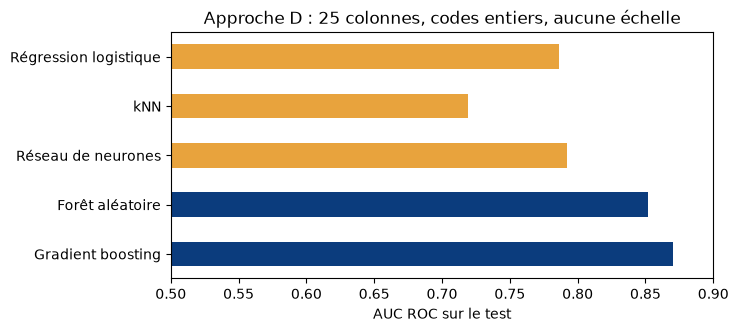

In [12]:
couleurs = ["#0B3C7D" if famille == "arbres" else "#E8A33D" for famille in resultats["famille"]]
ax = resultats.plot.barh(x="modele", y="auc", color=couleurs, legend=False, figsize=(7, 3.2))
ax.set_xlim(0.5, 0.9)
ax.set_xlabel("AUC ROC sur le test")
ax.set_ylabel("")
ax.set_title("Approche D : 25 colonnes, codes entiers, aucune échelle")
ax.invert_yaxis()
plt.show()

Deux groupes nets : les arbres (en bleu) au-dessus de 0,85, les autres familles (en orange) sous 0,80. Pour
mémoire, l'approche A (notebook 01) obtenait environ 0,87 avec ses deux arbres et entre 0,82 et 0,85 avec les
trois autres modèles, mais avec 365 colonnes. Le tableau complet est au notebook 05.

## 7. Lire les résultats : le prix de l'absence d'échelle

L'avertissement filtré plus haut, vérifié : combien d'itérations les deux modèles entraînés par une méthode de
gradient ont-ils faites, et quel était leur plafond ?

In [13]:
lr, reseau = pipelines["Régression logistique"][-1], pipelines["Réseau de neurones"][-1]
pd.DataFrame({"itérations": [lr.n_iter_[0], reseau.n_iter_], "plafond (max_iter)": [lr.max_iter, reseau.max_iter]},
             index=["Régression logistique", "Réseau de neurones"])

,itérations,plafond (max_iter)
Régression logistique,2000,2000
Réseau de neurones,59,200


La régression logistique s'est arrêtée au plafond : 2 000 itérations sur 2 000, sans converger. C'est exactement
ce que disait l'avertissement filtré. Le réseau, lui, s'est arrêté seul après 59 époques (arrêt précoce) : pas
d'avertissement, mais il apprend lui aussi sur des entrées non standardisées.

La preuve par la mise à l'échelle : la même régression logistique, avec les mêmes réglages, précédée d'un
`StandardScaler`.

In [14]:
debut = time.perf_counter()
lr_std = make_pipeline(clone(prep), StandardScaler(), modeles()["Régression logistique"]).fit(X_train, y_train)
duree = time.perf_counter() - debut
auc = roc_auc_score(y_test, lr_std.predict_proba(X_test)[:, 1])
print(f"itérations : {lr_std[-1].n_iter_[0]}, durée : {duree:.1f} s, AUC : {auc:.3f}")

itérations : 22, durée : 1.8 s, AUC : 0.786


Avec un `StandardScaler`, la régression logistique converge en 22 itérations et en environ 2 s, au lieu de 2 000
itérations et d'environ 80 s. Son AUC, en revanche, ne bouge pas (0,786) : la mise à l'échelle règle la convergence, pas
l'ordre inventé des codes. Pour ce modèle, il faudrait changer d'encodage (le one-hot de l'approche A).

Ce que ces chiffres disent, famille par famille (fiche réflexe du cours 2, slide 28) :

- **Les arbres** n'ont besoin ni d'échelle ni de one-hot : un code entier leur suffit. Le boosting natif fait à
  peu près jeu égal avec l'approche A. La forêt, sans support natif, perd un peu (0,852) : elle doit enchaîner les
  coupes pour regrouper des agents ou des pays dispersés dans l'ordre alphabétique.
- **La régression logistique** lit chaque code comme une quantité : pour elle, l'agent codé 168 pèse 168 fois
  l'agent codé 1. Elle chute à 0,786, et la standardisation ne la sauve pas.
- **Le kNN** (0,719) cumule les deux défauts : des distances dominées par `lead_time` et des codes sans voisinage
  réel. C'est lui qui perd le plus.
- **Le réseau** (0,792) fait un peu mieux que la régression grâce à ses couches cachées, mais il reste loin des
  arbres : codes arbitraires et échelles brutes, là encore.

> 💬 **Pour la salle.** Alors, faut-il toujours prendre des arbres ?
>
> *Piste : sur des données tabulaires, c'est souvent le meilleur point de départ : peu de préparation, rapides,
> robustes. Mais ils ne savent pas inventer une variable comme `taux_annul_passe_agent` (le taux d'annulation
> passé de l'agent, calculé à date) : le métier reste utile, l'approche B le montre. Et un modèle plus lisible,
> comme la régression logistique, demande une autre préparation : la préparation se choisit avec le modèle.
> Réponse chiffrée au notebook 05.*

## 8. Ce que regarde le boosting

L'importance par permutation mélange une colonne à la fois et mesure la baisse de l'AUC : plus la baisse est
forte, plus le modèle comptait sur cette colonne. Elle se calcule sur des données que le modèle n'a pas vues
(cours 2, slide 21, encadré) : ici, 5 000 réservations du test, 5 mélanges par colonne. Comme le pipeline contient
la préparation, on mélange les colonnes brutes.

In [15]:
echantillon = X_test.sample(5000, random_state=0)
permutation = permutation_importance(pipelines["Gradient boosting"], echantillon, y_test[echantillon.index],
                                     scoring="roc_auc", n_repeats=5, random_state=0)
importances = pd.DataFrame({"baisse_auc": permutation.importances_mean, "ecart_type": permutation.importances_std},
                           index=X_test.columns).sort_values("baisse_auc", ascending=False)
importances.head(10).round(4)

,baisse_auc,ecart_type
agent,0.1351,0.0050
country,0.1097,0.0036
deposit_type,0.0745,0.0009
total_of_special_requests,0.0411,0.0024
lead_time,0.0294,0.0018
customer_type,0.0162,0.0010
previous_bookings_not_canceled,0.0087,0.0004
market_segment,0.0041,0.0004
previous_cancellations,0.0033,0.0004
adr,0.0020,0.0004


Mélanger `agent` fait perdre environ 0,135 d'AUC, `country` 0,110 et `deposit_type` 0,074 : ces trois
catégorielles portent l'essentiel du modèle. Viennent ensuite `total_of_special_requests` (0,041) et `lead_time`
(0,029). Les écarts-types, entre 0,0004 et 0,005, sont petits devant ces baisses : le classement est stable.

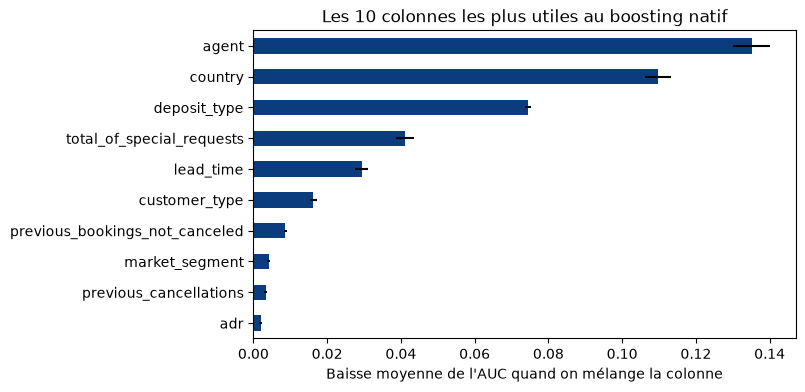

In [16]:
top = importances.head(10).iloc[::-1]
ax = top["baisse_auc"].plot.barh(xerr=top["ecart_type"], color="#0B3C7D", figsize=(7, 4))
ax.set_xlabel("Baisse moyenne de l'AUC quand on mélange la colonne")
ax.set_title("Les 10 colonnes les plus utiles au boosting natif")
plt.show()

Deux étiquettes à forte cardinalité, l'agent et le pays, devant tout le reste. Ce sont précisément les deux
colonnes que l'approche B transforme en historique « à date » (`taux_annul_passe_agent`,
`taux_annul_passe_country`) : les arbres les exploitent déjà comme étiquettes, mais ne savent pas calculer le
passé. Notez aussi `total_of_special_requests` en quatrième position : c'est la colonne « douteuse » du
notebook 00, dont il faudrait vérifier à quel moment les demandes sont saisies.

> 💬 **Pour la salle.** Seul, `market_segment` donnait 0,623 d'AUC (section 2). Pourquoi le mélanger ne
> coûte-t-il qu'environ 0,004 au boosting ?
>
> *Piste : l'information qu'il porte est déjà dans `agent`, `deposit_type` ou `customer_type` : quand on mélange
> l'une, les autres la remplacent. L'importance par permutation mesure ce qu'une colonne apporte **en plus** des
> autres ; elle sous-estime les colonnes redondantes (cours 2, slide 21, encadré).*

## À retenir

- **Numéroter, c'est inventer un ordre** : sur les codes d'`agent`, la régression logistique tombe à 0,508 d'AUC,
  contre 0,651 avec le one-hot ; un boosting retrouve 0,651 sur les mêmes codes.
- **Les arbres ignorent l'échelle** (la forêt donne 0,8524 avec ou sans standardisation) et se contentent d'un
  code entier : avec 25 colonnes au lieu de 365, le boosting natif atteint 0,870 en quelques secondes.
- **Le support natif des catégorielles** (`categorical_features`) supprime l'ordre inventé ; il ne rapporte ici
  que 0,002, mais il ne coûte rien.
- **La même préparation fait chuter les trois autres familles** : leurs AUC restent entre 0,719 et 0,792,
  contre 0,82 à 0,85 dans l'approche A. La préparation se choisit avec le modèle, c'est la fiche réflexe du
  cours 2 (slide 28).
- **Un `ConvergenceWarning` est un symptôme** : ici, l'absence de mise à l'échelle (2 000 itérations sur 2 000,
  contre 22 avec un `StandardScaler`). On ne le filtre qu'après l'avoir compris, précisément, et en le disant.